## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [25]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Abdullah Rana

**Date:** October 21st, 2026

---

# Q1. Token frequencies

total token occurrences: 276949
distinct tokens: 48691
tokens occurring once: 29404
proportion occurring once: 0.6039
median occurrences: 1.0
  token  occurrences
    new         1365
   date         1202
    get         1052
 please         1022
  enron          927
   like          923
   2002          869
  would          806
    one          798
message          795


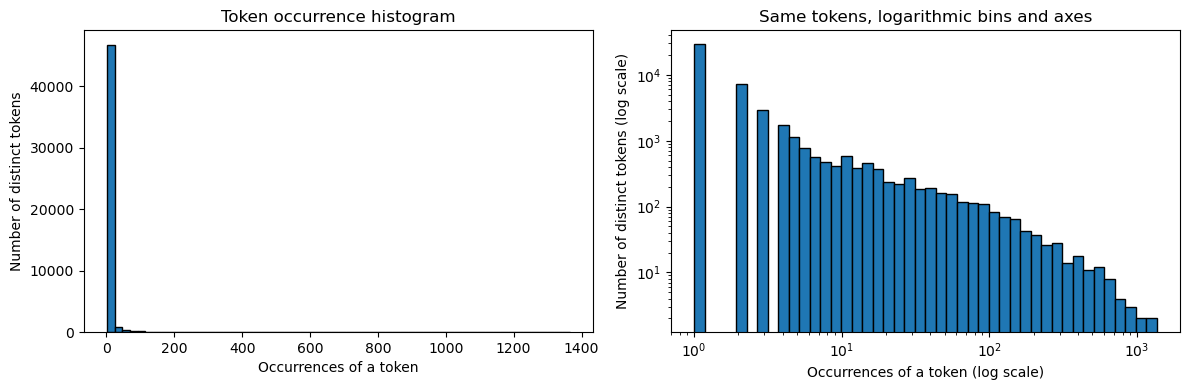

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from scipy.linalg import lstsq
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

pd.set_option('display.width', 140)

# Each value is the total number of occurrences of one distinct token.
occurrences = np.array(list(token_count.values()))
print('total token occurrences:', len(all_tokens))
print('distinct tokens:', len(occurrences))
print('tokens occurring once:', (occurrences == 1).sum())
print('proportion occurring once:', round((occurrences == 1).mean(), 4))
print('median occurrences:', np.median(occurrences))
print(pd.DataFrame(token_freq[:10], columns=['token', 'occurrences']).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(occurrences, bins=60, edgecolor='black')
axes[0].set_xlabel('Occurrences of a token')
axes[0].set_ylabel('Number of distinct tokens')
axes[0].set_title('Token occurrence histogram')
# The same data with logarithmic bins makes the long tail visible.
log_bins = np.geomspace(1, occurrences.max() + 1, 45)
axes[1].hist(occurrences, bins=log_bins, edgecolor='black')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Occurrences of a token (log scale)')
axes[1].set_ylabel('Number of distinct tokens (log scale)')
axes[1].set_title('Same tokens, logarithmic bins and axes')
plt.tight_layout()
plt.show()


The histogram is strongly right-skewed. Most tokens appear only a few times, while a small number appear hundreds or more than a thousand times. Of the 48,691 distinct tokens, 29,404 (about 60.4%) occur just once, and the median count is 1. The most common token is `new`, with 1,365 occurrences, followed by `date` (1,202) and `get` (1,052).

On the ordinary scale, almost everything is crowded into the first bin with a long tail to the right. The logarithmic view spreads out that tail and shows how quickly the number of tokens falls as occurrence counts rise. These are total token occurrences in the supplied vector, not the number of emails containing each token.

# Q2. Regression on the original tokens

### Q2.1 - Load the data and split 80/20

In [27]:
df = pd.read_parquet('data/Phishing_clean.parquet')
X = df.drop(columns=['Email Type'])
y = df['Email Type']

print('data shape:', df.shape)
print('missing values:', df.isna().sum().sum())
print('feature range:', X.min().min(), 'to', X.max().max())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100, stratify=y)
print('train:', X_train.shape, 'test:', X_test.shape)
print(pd.DataFrame({'train': y_train.value_counts().sort_index(),
                    'test': y_test.value_counts().sort_index()}))


# Check the supplied feature description without changing the predictor set.
feature_counts = X.sum()
print('all-zero columns in the whole dataset:', (feature_counts == 0).sum())
print('columns appearing in fewer than 15 emails:', (feature_counts < 15).sum())

data shape: (18634, 2712)
missing values: 0
feature range: 0 to 1
train: (14907, 2711) test: (3727, 2711)
            train  test
Email Type             
0            9057  2265
1            5850  1462
all-zero columns in the whole dataset: 55
columns appearing in fewer than 15 emails: 170


The file has 18,634 emails and 2,711 token columns, all coded 0 or 1, with no missing values. I separate `Email Type` from the predictors and use 80% for training (14,907 emails) and 20% for testing (3,727). `random_state=100` makes the split reproducible, and `stratify=y` keeps the phishing share close to the same in both sets. The target is 1 for phishing and 0 otherwise.

The actual feature counts do not fully match the question's description: 55 columns are all zero, and 170 columns occur in fewer than 15 emails (55 all-zero columns plus 115 nonzero columns). I keep all 2,711 supplied predictors, but use a rank-aware least-squares fit below.

### Q2.2 - Fit linear regression and calculate $R^2$

In [28]:
# Center the training data so the intercept is not penalized or truncated.
X_train_array = X_train.to_numpy(dtype=float)
X_test_array = X_test.to_numpy(dtype=float)
train_mean = X_train_array.mean(axis=0)
y_train_mean = y_train.mean()
X_centered = X_train_array - train_mean

# Explicitly discard numerical zero singular values. This computes the
# minimum-norm OLS solution even when predictors are linearly dependent.
# The relative tolerance is fixed in advance, not selected on test outcomes.
linear_coef, _, linear_rank, linear_singular_values = lstsq(
    X_centered, y_train.to_numpy() - y_train_mean,
    cond=1e-10, lapack_driver='gelsd')
linear_intercept = y_train_mean - train_mean @ linear_coef
linear_train_pred = X_train_array @ linear_coef + linear_intercept
linear_test_pred = X_test_array @ linear_coef + linear_intercept
linear_train_r2 = r2_score(y_train, linear_train_pred)
linear_test_r2 = r2_score(y_test, linear_test_pred)

print('centered training matrix rank:', linear_rank, 'of', X_train.shape[1])
print('training R-squared:', f'{linear_train_r2:.6f}')
print('test R-squared:', f'{linear_test_r2:.6f}')

centered training matrix rank: 2639 of 2711
training R-squared: 0.768863
test R-squared: 0.656955


The training $R^2$ is 0.768863, and the test $R^2$ is 0.656955. The model explains about 76.9% of the variation in the training outcome and 65.7% in the held-out outcome. The lower test value shows that some of the training fit does not carry over to new emails, which is consistent with overfitting in a regression with so many predictors.

These are $R^2$ values, not percentages of emails classified correctly. I use ordinary linear regression as requested even though the outcome is binary, so its fitted values are not constrained to lie between 0 and 1.

The centered training matrix has rank 2,639 rather than 2,711, so ordinary least-squares coefficients are not unique. The explicit SVD cutoff treats numerical zero singular values as zero and returns the minimum-norm solution. Without that cutoff, a solver can assign huge, opposite coefficients to dependent tokens, making test predictions numerically unstable. This is a numerical safeguard for OLS, not a new regression penalty or a test-selected tuning choice.

### Q2.3 - Words with the largest absolute coefficients

In [29]:
coefficients = pd.DataFrame({'token': X.columns,
                             'coefficient': linear_coef,
                             'emails containing token': X.sum().to_numpy(),
                             'training emails containing token': X_train.sum().to_numpy()})
# These descriptive shares help interpret rare tokens; they do not tune the model.
coefficients['training phishing share when present'] = (
    X_train.mul(y_train, axis=0).sum() / X_train.sum().replace(0, np.nan)).to_numpy()
coefficients['absolute coefficient'] = coefficients['coefficient'].abs()
largest_coefficients = coefficients.sort_values(
    'absolute coefficient', ascending=False).head(15)
print(largest_coefficients.to_string(index=False, float_format=lambda x: f'{x:.6f}'))

            token  coefficient  emails containing token  training emails containing token  training phishing share when present  absolute coefficient
background-image:    -0.782907                       31                                26                              0.038462              0.782907
        localized     0.777696                       31                                24                              1.000000              0.777696
              rcs     0.552824                       18                                13                              0.000000              0.552824
             fax,     0.551482                       18                                16                              1.000000              0.551482
       helvetica,     0.551048                       19                                17                              0.882353              0.551048
{text-decoration:     0.542073                       17                                14           

The largest coefficient in absolute value belongs to `background-image:` at -0.782907, followed by `localized` at 0.777696, `rcs` at 0.552824, `fax,` at 0.551482, and `helvetica,` at 0.551048. Other large coefficients include `{text-decoration:` (0.542073), `form.` (0.524322), `zdnet` (-0.523850), and `intervention` (-0.521406). The table reports the top 15 by absolute size, retaining the signs.

Since the predictors are binary, a coefficient is the fitted change when that token switches from absent to present, holding the other tokens fixed. Positive coefficients raise the predicted phishing outcome, and negative coefficients lower it. These are model-based conditional associations, not causal effects or measures of how often a word appears. For dependent tokens, changing one while holding all the others fixed may not be represented in the training data. Correlated words and formatting tokens can share information, so a large individual coefficient can be sensitive to which other tokens are included.

These top 15 tokens are rare: each occurs in only 10 to 56 emails in the full dataset and 7 to 44 training emails. Several are nearly exclusive to one class in training. For example, all 24 training emails containing `localized` are phishing, while only 1 of 26 containing `background-image:` is phishing (a share of 0.038462). Those small, unusually homogeneous groups can produce large coefficients without establishing that a token is a reliable predictor in general. The training phishing shares in the table describe each token on its own; they need not agree with its conditional regression coefficient after accounting for other tokens. The displayed coefficients are one minimum-norm OLS solution, not uniquely identified effects of individual words when the predictors are linearly dependent.

# Q3. The first two principal components

explained variance ratios: [0.01113091 0.00860868]
variance explained by both: 0.01973959224579444


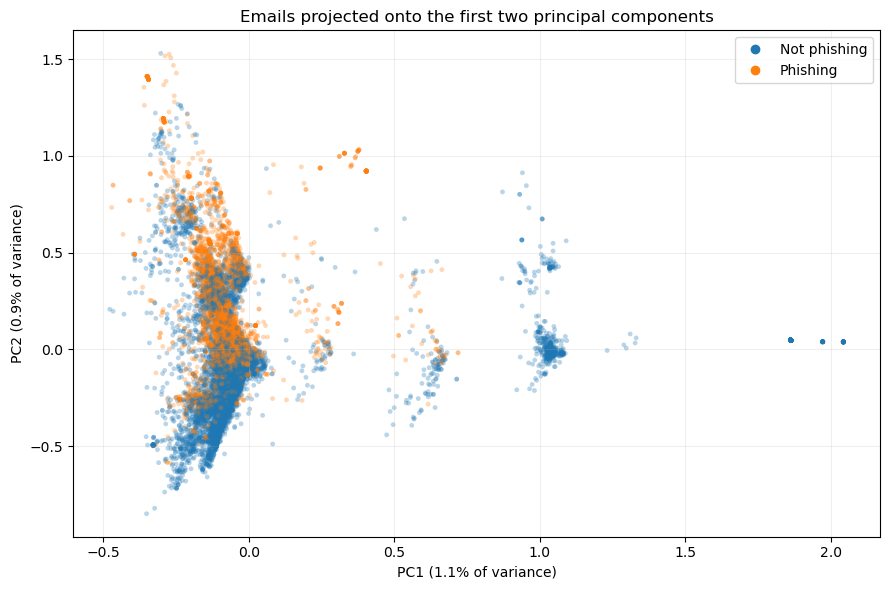

In [30]:
# This is a descriptive plot of all emails; the outcome is only used for color.
# All features are binary, so use their original scale and let PCA center them.
pca_two = PCA(n_components=2, svd_solver='randomized', random_state=100)
X_two = pca_two.fit_transform(X)

print('explained variance ratios:', pca_two.explained_variance_ratio_)
print('variance explained by both:', pca_two.explained_variance_ratio_.sum())

# Mix the drawing order so one entire class is not placed on top of the other.
from matplotlib.lines import Line2D
plot_order = np.random.default_rng(100).permutation(len(y))
plot_colors = np.where(y.to_numpy() == 1, 'tab:orange', 'tab:blue')
plt.figure(figsize=(9, 6))
plt.scatter(X_two[plot_order, 0], X_two[plot_order, 1], s=12, alpha=0.3,
            c=plot_colors[plot_order], edgecolors='none')
plt.xlabel(f'PC1 ({100 * pca_two.explained_variance_ratio_[0]:.1f}% of variance)')
plt.ylabel(f'PC2 ({100 * pca_two.explained_variance_ratio_[1]:.1f}% of variance)')
plt.title('Emails projected onto the first two principal components')
plt.legend(handles=[
    Line2D([], [], marker='o', linestyle='', color='tab:blue', label='Not phishing'),
    Line2D([], [], marker='o', linestyle='', color='tab:orange', label='Phishing')])
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


The two email types overlap heavily in the large cloud near PC1 = 0, so the first two components do not cleanly separate phishing from legitimate emails. There is still some structure: phishing emails are more concentrated toward positive PC2 values in that cloud, while the lower part contains more non-phishing emails. Several smaller concentrations farther to the right, especially around PC1 = 1, are mostly non-phishing.

PC1 explains about 1.11% of the feature variance and PC2 about 0.86%, for only 1.97% together. This is therefore a limited two-dimensional view of a high-dimensional dataset. Overlap here does not mean that the remaining components contain no useful predictive information. PCA finds directions of variation in the token indicators without using the phishing labels; color lets us compare the labels afterward.

The points are drawn in a reproducibly shuffled order so neither class is always drawn last. Dense overlapping colors still should not be read as exact class proportions.

# Q4. Regression on 2,610 principal components

In [31]:
# Reuse the Q2 split and the assignment's fixed choice of 2,610 components.
# Fit PCA only on training features to avoid test leakage.
pca_regression = PCA(n_components=2610, svd_solver='full')
X_train_pc = pca_regression.fit_transform(X_train)
X_test_pc = pca_regression.transform(X_test)

# Use the same explicit numerical rank tolerance as the original-token fit.
pc_mean = X_train_pc.mean(axis=0)
pc_coef, _, pc_rank, _ = lstsq(
    X_train_pc - pc_mean, y_train.to_numpy() - y_train_mean,
    cond=1e-10, lapack_driver='gelsd')
pc_intercept = y_train_mean - pc_mean @ pc_coef
pc_train_pred = X_train_pc @ pc_coef + pc_intercept
pc_test_pred = X_test_pc @ pc_coef + pc_intercept
pc_train_r2 = r2_score(y_train, pc_train_pred)
pc_test_r2 = r2_score(y_test, pc_test_pred)

comparison = pd.DataFrame({
    'model': ['Original 2,711 tokens', 'First 2,610 PCs'],
    'training R-squared': [linear_train_r2, pc_train_r2],
    'test R-squared': [linear_test_r2, pc_test_r2]
})
print(comparison.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
print('retained PC matrix rank:', pc_rank)
print('training feature variance retained:',
      f'{pca_regression.explained_variance_ratio_.sum():.8f}')

                model  training R-squared  test R-squared
Original 2,711 tokens            0.768863        0.656955
      First 2,610 PCs            0.768305        0.657660
retained PC matrix rank: 2610
training feature variance retained: 0.99986954


With 2,610 principal components, training $R^2$ is 0.768305 and test $R^2$ is 0.657660. The original-token regression has training $R^2$ of 0.768863 and test $R^2$ of 0.656955. PCA therefore lowers training fit slightly (by about 0.000558) and improves test fit slightly (by about 0.000705). Performance is essentially the same on this split; the small test improvement is not evidence that PCA will always perform better.

The retained components explain about 99.987% of the training feature variance. Removing just 101 low-variance directions therefore changes the fit very little. Both models use exactly the same training and test emails. For this predictive comparison, PCA is fitted only on the training predictors and then applied to the test predictors; the all-email PCA in Q3 is used only for its descriptive plot.

# Q5. Why use principal components?

PCA replaces overlapping token indicators with uncorrelated combinations, ordered by how much feature variation they explain. Keeping components with nonzero, sufficiently large variance avoids directions where regression would divide by zero or a tiny number. That improves numerical stability, especially here, where the centered token matrix is rank-deficient. Keeping all components, including null directions, would not solve that problem by itself.

Dropping low-variance directions can also reduce sensitivity to noise and overfitting. Here the assignment keeps 2,610 of 2,711 components, so the dimension reduction is small and the test improvement over stable OLS is small too. PCA ignores the outcome, so low-variance directions could still be predictive and better test performance is not guaranteed. The tradeoff is interpretation: a component combines many tokens instead of giving a coefficient for one word.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** ChatGPT 6.1 Sol

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [32]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]